# Vigía — Análisis de una sesión · Session analysis

**ES:** Este cuaderno lee un CSV exportado por la app (botón *Descargar CSV*) y muestra cómo evolucionan los indicadores de fatiga. Por defecto usa `sample_data/synthetic_session.csv`, un viaje **sintético** de 30 min generado con `scripts/simulate_session.mjs` (no contiene datos de ninguna persona).

**EN:** This notebook reads a CSV exported by the app (*Download CSV* button) and shows how the fatigue indicators evolve. By default it uses `sample_data/synthetic_session.csv`, a **synthetic** 30-min drive generated with `scripts/simulate_session.mjs` (no real person's data).

> Privacidad / Privacy: the CSV only has per-second numbers (no images, no face landmarks).

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

from vigia_analysis import load_session, summarize, per_minute
from vigia_analysis.plots import plot_session

# Cambiá esta ruta por tu propio CSV / Replace with your own CSV
DATA = Path("../sample_data/synthetic_session.csv")
df = load_session(DATA)
df.head()

,t_s,engine,fps,proc_ms,face_ratio,ear_mean,mar_max,eye_closed_ratio,blink_score_mean,jaw_open_max,...,face_lost,critical_closures,c_perclos,c_long_closures,c_yawns,c_blink_duration,c_head,score,level,minute
0,0,synthetic,30,NaN,1.0,0.3005,0.0830,0.000,0.0500,0.03,...,0,0,0.0,0.0,0,0.0,0.0,0,ok,0.000000
1,1,synthetic,30,NaN,1.0,0.2989,0.0833,0.000,0.0500,0.03,...,0,0,0.0,0.0,0,0.0,0.0,0,ok,0.016667
2,2,synthetic,30,NaN,1.0,0.2663,0.0790,0.167,0.1833,0.03,...,0,0,0.0,0.0,0,0.0,0.0,0,ok,0.033333
3,3,synthetic,30,NaN,1.0,0.2995,0.0816,0.000,0.0500,0.03,...,0,0,0.0,0.0,0,0.0,0.0,0,ok,0.050000
4,4,synthetic,30,NaN,1.0,0.3017,0.0749,0.000,0.0500,0.03,...,0,0,0.0,0.0,0,0.0,0.0,0,ok,0.066667


In [2]:
summary = summarize(df)
summary

{'duration_min': 30.0,
 'engine': 'synthetic',
 'mean_fps': 30.0,
 'score_mean': 38.7,
 'score_max': 95,
 'perclos_max': 0.161,
 'pct_time_per_level': {'ok': 42.8,
  'mild': 21.2,
  'moderate': 23.1,
  'high': 12.9},
 'events': {'blinks': 444,
  'long_closures': 10,
  'yawns': 10,
  'head_deviations': 5,
  'face_lost': 4,
  'critical_closures': 1}}

## 1. Evolución del índice de fatiga · Fatigue score over time

Las franjas de color son los niveles (verde = alerta, amarillo = leve, naranja = moderada, rojo = alta). El panel inferior marca los eventos: cierres largos, bostezos, cabeceos y el cierre crítico (microsueño).

Coloured bands are the levels (green = alert … red = high). The bottom panel marks events: long closures, yawns, head nods and the critical closure (microsleep).

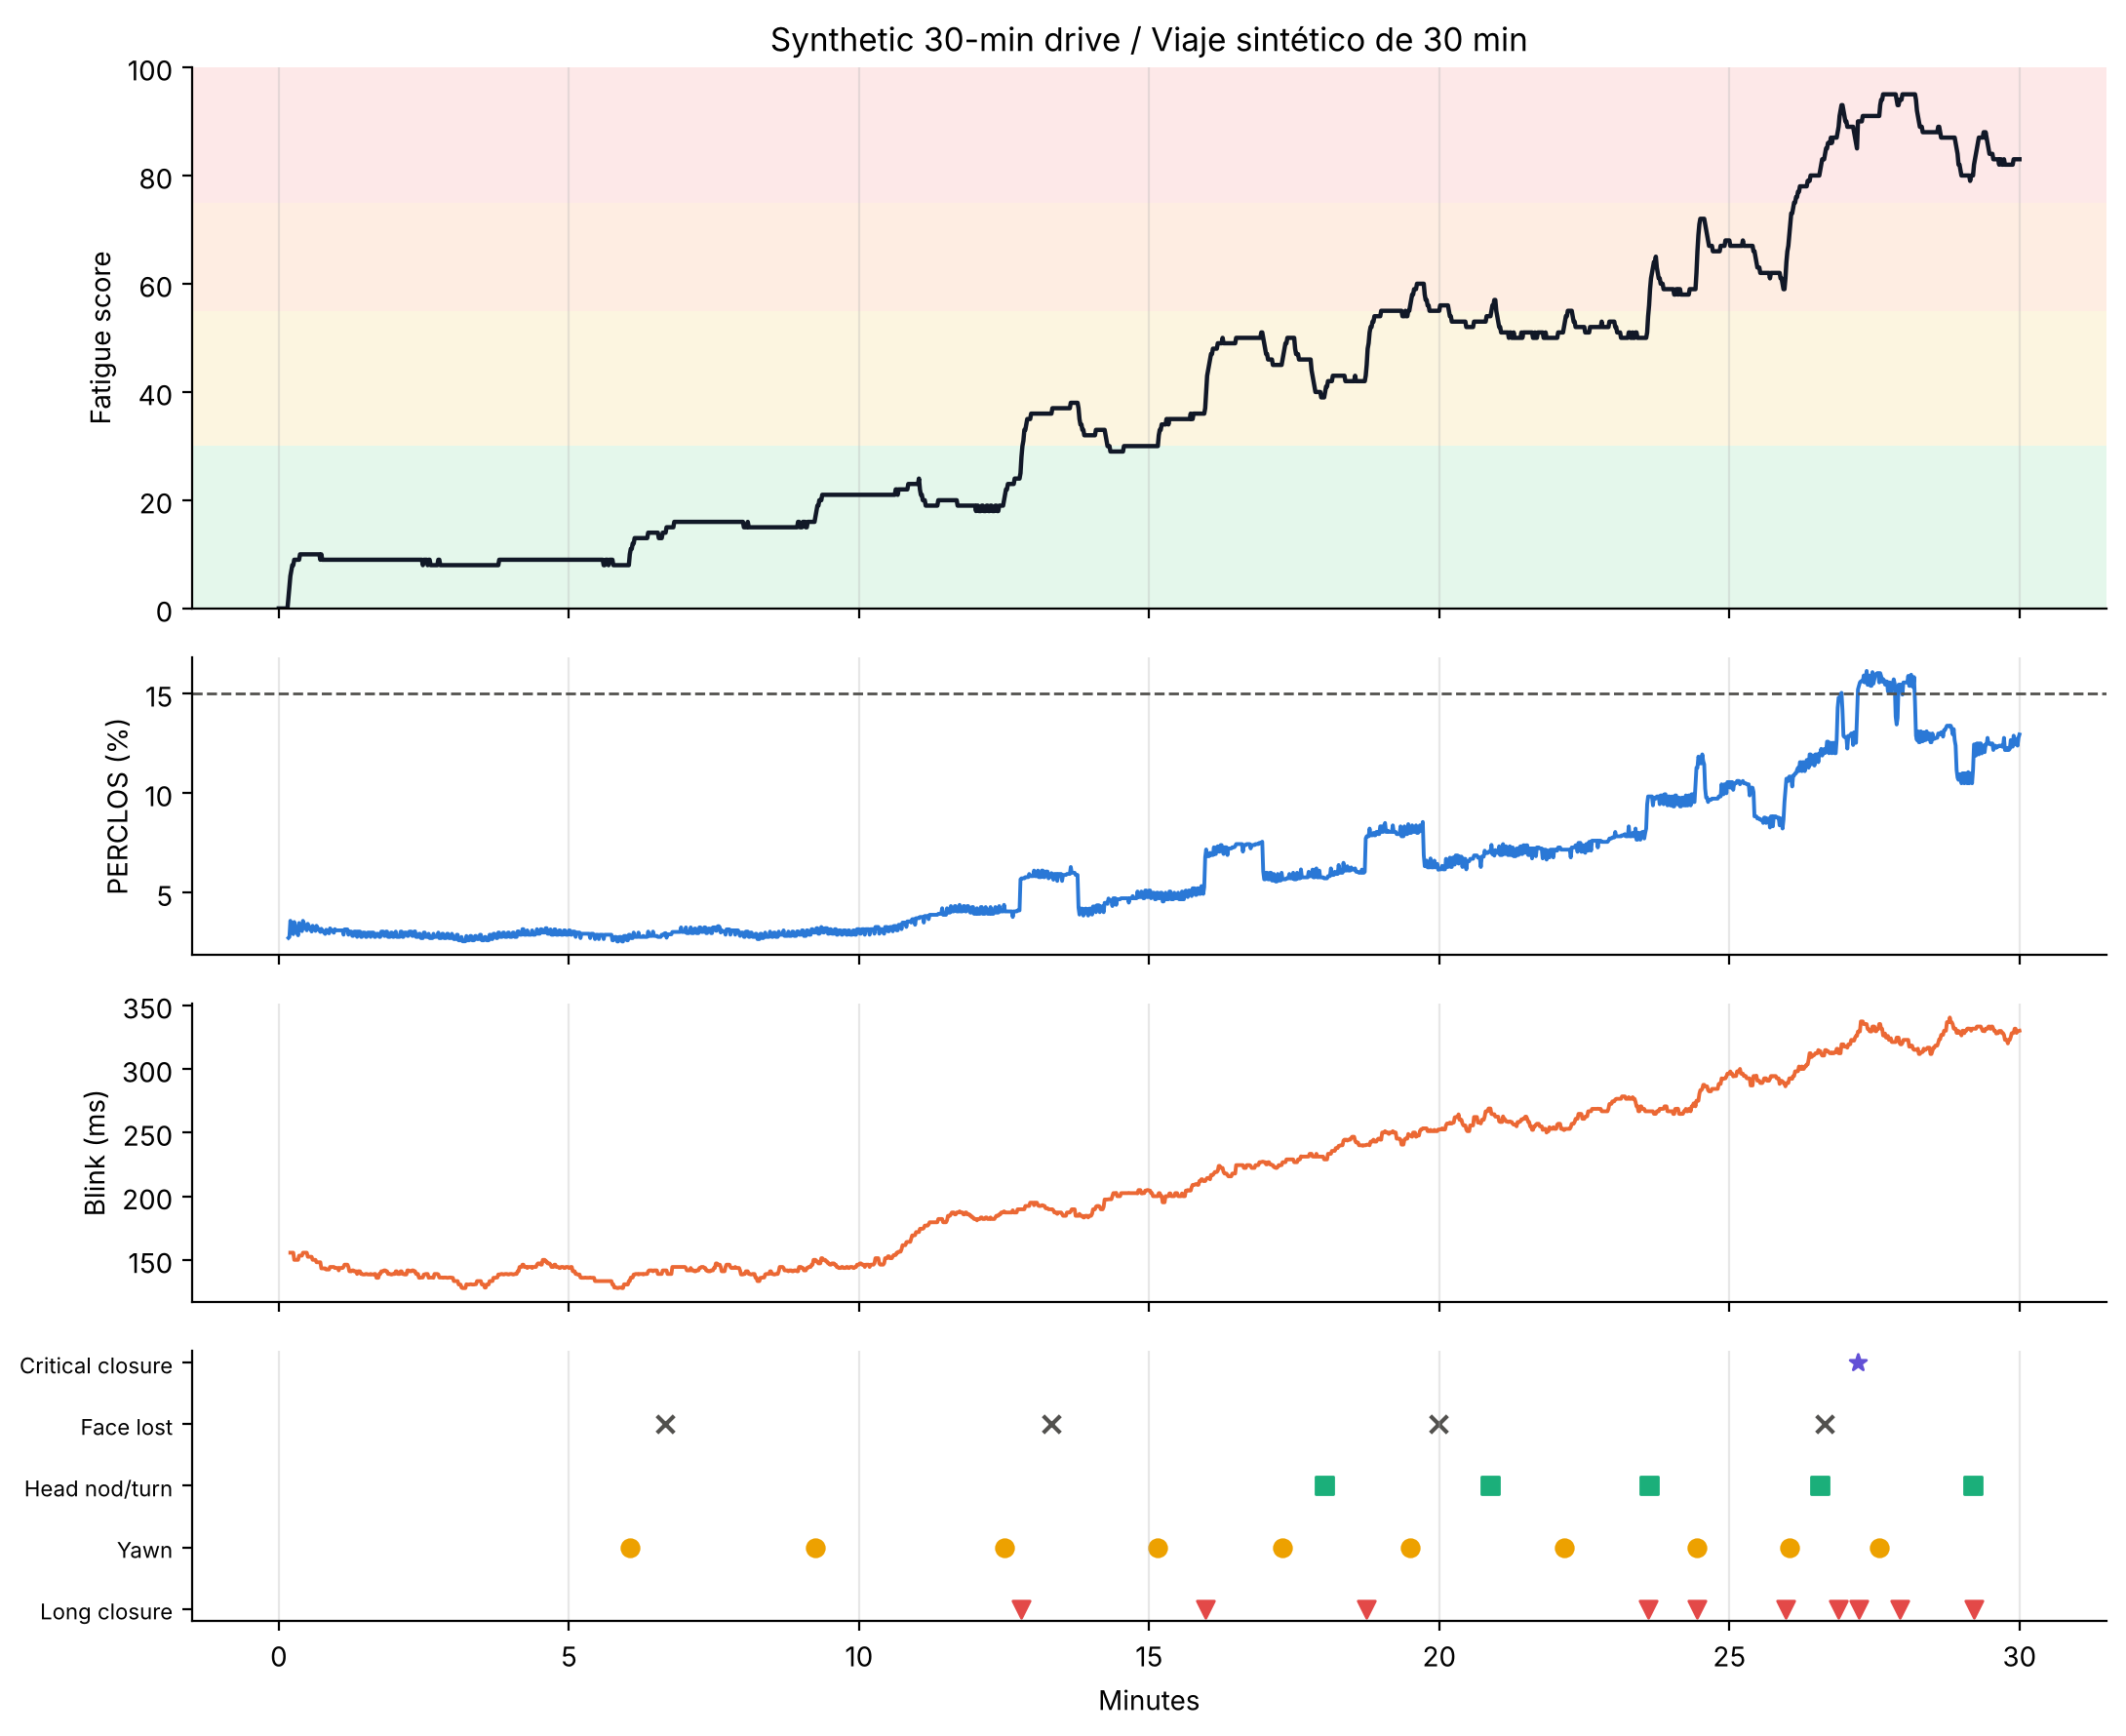

In [3]:
fig = plot_session(df, title="Synthetic 30-min drive / Viaje sintético de 30 min")
plt.show()

## 2. Indicadores por minuto · Per-minute indicators

Agregar por minuto deja una tabla lista para modelar (una fila = un minuto de manejo).
Aggregating per minute gives a modelling-ready table (one row = one minute of driving).

In [4]:
m = per_minute(df)
m.round(2).iloc[::5]

,score,perclos,blink_rate,avg_blink_ms,ear,blinks,long_closures,yawns,head_deviations,face_lost,critical_closures
min,,,,,,,,,,,
0,7.55,0.03,12.71,149.20,0.29,13,0,0,0,0,0
5,8.72,0.03,12.73,134.41,0.29,13,0,0,0,0,0
10,21.50,0.03,12.73,153.62,0.29,13,0,0,0,0,0
15,34.28,0.05,14.45,203.58,0.27,15,1,1,0,0,0
20,53.80,0.07,14.80,258.97,0.27,16,0,0,1,0,0
25,64.22,0.10,17.87,292.80,0.25,18,1,0,0,0,0
30,83.00,0.13,20.00,330.00,0.18,1,0,0,0,0,0


In [5]:
# ¿Qué indicadores acompañan al índice? / Which indicators move with the score?
cols = ["perclos", "avg_blink_ms", "blink_rate", "long_closures", "yawns", "head_deviations"]
m[cols].corrwith(m["score"]).sort_values(ascending=False).round(2)

avg_blink_ms       0.98
perclos            0.98
blink_rate         0.95
long_closures      0.52
head_deviations    0.38
yawns              0.21
dtype: float64

### ⚠️ Lectura honesta · Honest reading

**ES:** En datos sintéticos estas correlaciones son altas *por construcción*: el índice se calcula con esos mismos indicadores. Esto **no valida** el detector. Para validarlo hace falta una etiqueta independiente de la cámara, por ejemplo la escala de somnolencia de Karolinska (KSS) o un test de reacción (PVT). Ese es el próximo paso de la hoja de ruta.

**EN:** On synthetic data these correlations are high *by construction*: the score is computed from these same indicators. This does **not validate** the detector. Validation needs a label that is independent of the camera, such as the Karolinska Sleepiness Scale (KSS) or a reaction-time test (PVT). That is the next step on the roadmap.

In [6]:
# Tiempo en cada nivel por bloque de 5 minutos / Time in each level per 5-minute block
block = (df["t_s"] // 300 * 5).rename("minute_block")
pd.crosstab(block, df["level"], normalize="index").mul(100).round(0)

level,ok,mild,moderate,high
minute_block,,,,
0,100.0,0.0,0.0,0.0
5,100.0,0.0,0.0,0.0
10,57.0,43.0,0.0,0.0
15,0.0,81.0,19.0,0.0
20,0.0,3.0,97.0,0.0
25,0.0,0.0,23.0,77.0
30,0.0,0.0,0.0,100.0


## 3. Próximos pasos · Next steps

1. **02 — Benchmark:** comparar el motor clásico (Haar) con MediaPipe sobre un dataset público de somnolencia (p. ej. UTA-RLDD, revisando su licencia) con precisión, recall, F1 y curvas ROC para elegir umbrales. / Compare Haar vs MediaPipe on a public drowsiness dataset with precision, recall, F1 and ROC curves to choose thresholds.
2. **03 — Etiquetas propias · Own labels:** sesiones piloto con consentimiento informado + KSS cada 5 min + PVT de 3 min. / Pilot sessions with informed consent + KSS every 5 min + 3-min PVT.
3. **04 — Modelo · Model:** reemplazar los pesos manuales por una regresión logística entrenada con esas etiquetas y exportarla a JavaScript. / Replace hand-set weights with a logistic regression trained on those labels and export it to JavaScript.